# UPI Transaction Risk Analysis: Insights and Analysis

**Goal:** find out when, where and how UPI payments fail or get flagged, and turn the numbers into decisions a payments or risk team could act on.

**Data:** Kaggle "UPI Transactions 2024" (250,000 rows, Jan–Dec 2024). The data is **synthetic**, so every result shows the *method* and is not a statement about real UPI traffic. A fraud flag is a label in the dataset, not confirmed fraud.

**How to run:** put this notebook in the same folder as `archive (29).zip` and run all cells. It needs only `pandas`, `numpy`, `matplotlib` and `scipy`, and it does not need MySQL. The SQL versions of the KPI queries are in `sql code1.sql`.

## Key takeaways

1. **Evenings carry the load.** 17:00–20:59 holds about 31% of all transactions.
2. **Money is concentrated.** Payments above ₹10,000 are 0.7% of transactions but 7.4% of value, and the top 10% of payments hold 43% of all value.
3. **Count and value tell different stories.** Education is 3% of payments but 12% of value, and Transport is 8% of payments but 2% of value.
4. **Failures look random.** The failure rate is about 5% for every bank, device, network, category, state and age group. No difference survives a multiple-testing correction.
5. **One lead worth investigating.** Fraud flags are more common above ₹5,000 (0.30% vs 0.19%), but this rests on only 33 cases and is a hypothesis, not a conclusion.

## 1. Setup and data check

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, fisher_exact

# Chart style: one accent colour, quiet grid, clear text hierarchy
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#c3c2b7"
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 14, "font.size": 10,
})
pd.options.display.float_format = "{:,.2f}".format

In [2]:
DATA_PATH = "archive (29).zip"   # the zip in this repo (or point to upi_transactions_2024.csv)
df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])

print(f"Rows: {len(df):,}   Columns: {df.shape[1]}")
print(f"Date range: {df['timestamp'].min():%d %b %Y} to {df['timestamp'].max():%d %b %Y}")
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate transaction IDs:", int(df["transaction id"].duplicated().sum()))
print("hour_of_day agrees with timestamp:", bool((df["timestamp"].dt.hour == df["hour_of_day"]).all()))
print("day_of_week agrees with timestamp:", bool((df["timestamp"].dt.day_name() == df["day_of_week"]).all()))
print("Statuses:", df["transaction_status"].value_counts().to_dict())
df.head()

Rows: 250,000   Columns: 17
Date range: 01 Jan 2024 to 30 Dec 2024
Missing values: 0
Duplicate rows: 0
Duplicate transaction IDs: 0
hour_of_day agrees with timestamp: True
day_of_week agrees with timestamp: True
Statuses: {'SUCCESS': 237624, 'FAILED': 12376}


,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0


In [3]:
AMOUNT = "amount (INR)"

df["is_failed"] = (df["transaction_status"].str.strip().str.upper() == "FAILED").astype(int)
df["month"] = df["timestamp"].dt.to_period("M").astype(str)

bands = ["₹0–500", "₹501–2,000", "₹2,001–5,000", "₹5,001–10,000", "₹10,000+"]
df["amount_band"] = pd.cut(df[AMOUNT], [0, 500, 2000, 5000, 10000, np.inf],
                           labels=bands, include_lowest=True)
df["high_value"] = df[AMOUNT] > 5000

df[["is_failed", "fraud_flag", "month", "amount_band", "high_value"]].head()

,is_failed,fraud_flag,month,amount_band,high_value
0,0,0,2024-10,"₹501–2,000",False
1,0,0,2024-04,"₹501–2,000",False
2,0,0,2024-04,₹0–500,False
3,0,0,2024-01,"₹2,001–5,000",False
4,0,0,2024-01,"₹501–2,000",False


## 2. Headline KPIs

In [4]:
total_value = df[AMOUNT].sum()
failed_value = df.loc[df["is_failed"] == 1, AMOUNT].sum()

kpi = pd.DataFrame({
    "KPI": [
        "Total transactions", "Total value", "Average amount", "Median amount",
        "Failure rate", "Failed value (payments at risk)", "Fraud-flagged transactions",
    ],
    "Value": [
        f"{len(df):,}",
        f"₹{total_value / 1e7:,.2f} Cr",
        f"₹{df[AMOUNT].mean():,.0f}",
        f"₹{df[AMOUNT].median():,.0f}",
        f"{df['is_failed'].mean() * 100:.2f}%  ({df['is_failed'].sum():,} failed)",
        f"₹{failed_value / 1e7:,.2f} Cr  ({failed_value / total_value * 100:.1f}% of value)",
        f"{df['fraud_flag'].sum():,}  ({df['fraud_flag'].mean() * 100:.2f}%)",
    ],
}).set_index("KPI")
kpi

,Value
KPI,
Total transactions,"250,000"
Total value,₹32.79 Cr
Average amount,"₹1,312"
Median amount,₹629
Failure rate,"4.95% (12,376 failed)"
Failed value (payments at risk),₹1.68 Cr (5.1% of value)
Fraud-flagged transactions,480 (0.19%)


About 1 in 20 payments fails, and failed payments account for about 5% of value. This is value that did not go through, not money lost. Fraud flags are rare (0.19%), so any fraud comparison rests on small counts.

## 3. When do people pay?

Busiest hour: 19:00 (8.5% of transactions)
Quietest hours: 03:00 (0.5%) and 04:00 (0.5%)
Evening window 17:00–20:59: 31.3% of transactions


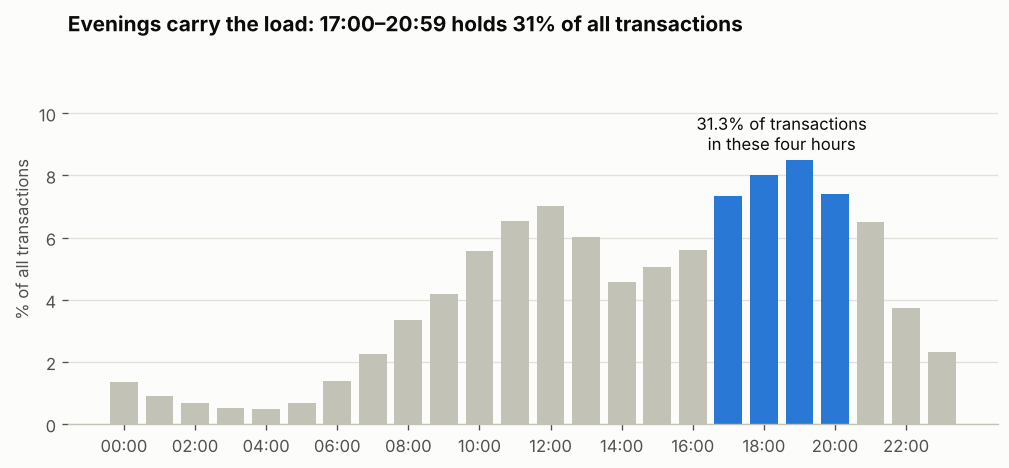

In [5]:
hour_share = df["hour_of_day"].value_counts(normalize=True).sort_index() * 100
peak = hour_share.loc[17:20]

fig, ax = plt.subplots(figsize=(10, 4))
colors = [BLUE if 17 <= h <= 20 else GRAY for h in hour_share.index]
ax.bar(hour_share.index, hour_share.values, color=colors, width=0.78)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 2)])
ax.set_ylabel("% of all transactions")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, peak.max() * 1.4)
ax.set_title(f"Evenings carry the load: 17:00–20:59 holds {peak.sum():.0f}% of all transactions")
ax.annotate(f"{peak.sum():.1f}% of transactions\nin these four hours",
            xy=(18.5, peak.max() + 0.2), ha="center", va="bottom", color=INK, fontsize=10)
plt.show()

print(f"Busiest hour: {hour_share.idxmax():02d}:00 ({hour_share.max():.1f}% of transactions)")
print(f"Quietest hours: 03:00 ({hour_share.loc[3]:.1f}%) and 04:00 ({hour_share.loc[4]:.1f}%)")
print(f"Evening window 17:00–20:59: {peak.sum():.1f}% of transactions")

### Insight 1: payments peak in the evening

**Finding:** Traffic is very uneven across the day.
**Evidence:** The four hours from 17:00 to 20:59 carry 31.3% of all transactions. 19:00 is the busiest hour (8.5%), while 03:00 and 04:00 each carry only 0.5%.
**So what:** Anything that goes wrong in the evening hits far more payments than the same problem at night.
**Recommended action:** Schedule maintenance and releases for 03:00–05:00, and size capacity and alerting for the evening window.

## 4. Where is the money?

Average ₹1,312 vs median ₹629
The largest 10% of transactions hold 43.0% of total value


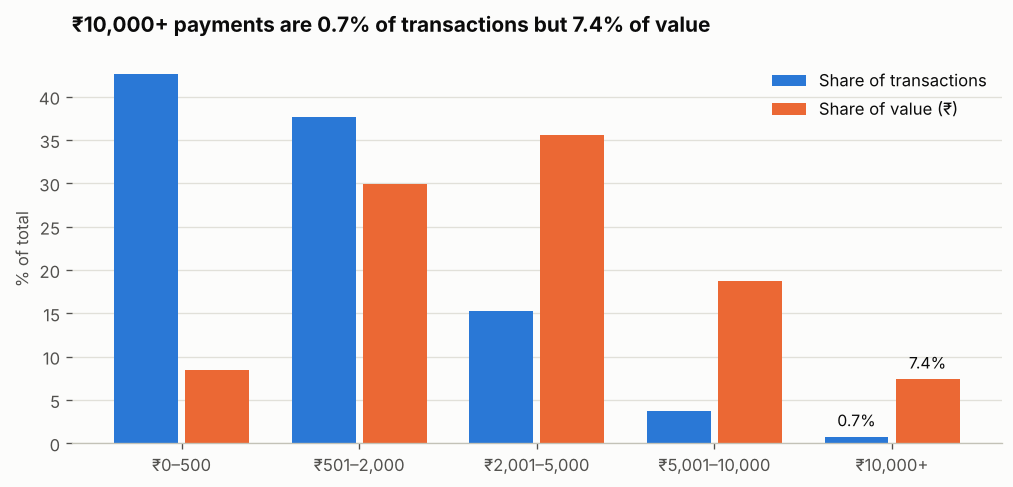

,transactions,Share of transactions,Share of value (₹)
amount_band,,,
₹0–500,106624,42.65,8.41
"₹501–2,000",94221,37.69,29.92
"₹2,001–5,000",38199,15.28,35.61
"₹5,001–10,000",9151,3.66,18.69
"₹10,000+",1805,0.72,7.37


In [6]:
g = df.groupby("amount_band", observed=True).agg(transactions=(AMOUNT, "size"), value=(AMOUNT, "sum"))
g["Share of transactions"] = g["transactions"] / g["transactions"].sum() * 100
g["Share of value (₹)"] = g["value"] / g["value"].sum() * 100

x = np.arange(len(g))
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(x - 0.2, g["Share of transactions"], 0.36, color=BLUE, label="Share of transactions")
ax.bar(x + 0.2, g["Share of value (₹)"], 0.36, color=ORANGE, label="Share of value (₹)")
ax.set_xticks(x)
ax.set_xticklabels(g.index)
ax.set_ylabel("% of total")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper right")
last = g.iloc[-1]
ax.set_title(f"₹10,000+ payments are {last['Share of transactions']:.1f}% of transactions "
             f"but {last['Share of value (₹)']:.1f}% of value")
for i, col, dx in [(len(g) - 1, "Share of transactions", -0.2), (len(g) - 1, "Share of value (₹)", 0.2)]:
    ax.text(i + dx, g.iloc[i][col] + 0.8, f"{g.iloc[i][col]:.1f}%", ha="center", va="bottom", fontsize=9.5)
plt.show()

top10 = df[AMOUNT].nlargest(int(len(df) * 0.10)).sum() / df[AMOUNT].sum() * 100
print(f"Average ₹{df[AMOUNT].mean():,.0f} vs median ₹{df[AMOUNT].median():,.0f}")
print(f"The largest 10% of transactions hold {top10:.1f}% of total value")
g[["transactions", "Share of transactions", "Share of value (₹)"]]

### Insight 2: a few large payments carry a lot of value

**Finding:** Value is far more concentrated than volume.
**Evidence:** The average payment is ₹1,312 but the median is ₹629. The largest 10% of transactions hold 43.0% of all value. Payments of ₹10,000+ are 0.7% of transactions but 7.4% of value, while payments up to ₹500 are 42.6% of transactions but only 8.4% of value.
**So what:** Counting transactions understates the importance of large payments.
**Recommended action:** Report reliability and risk by value as well as by count, and monitor high-value payments separately.

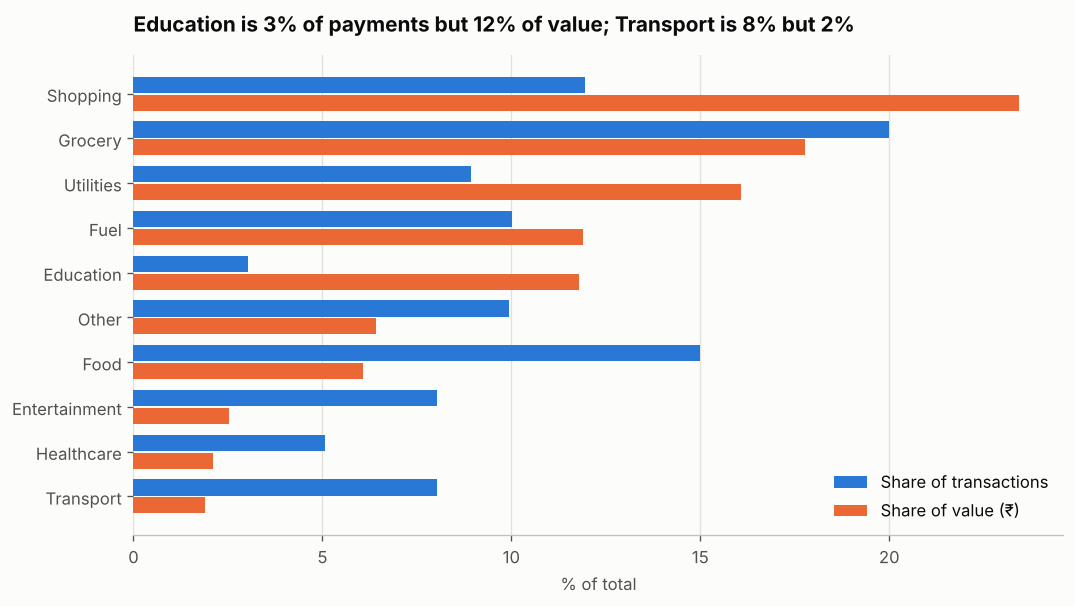

,Share of transactions,Share of value (₹)
merchant_category,,
Shopping,11.95,23.44
Grocery,19.99,17.77
Utilities,8.94,16.08
Fuel,10.03,11.89
Education,3.04,11.80
Other,9.93,6.43
Food,14.99,6.07
Entertainment,8.04,2.53
Healthcare,5.07,2.10


In [7]:
cat = df.groupby("merchant_category").agg(n=(AMOUNT, "size"), value=(AMOUNT, "sum"))
cat["Share of transactions"] = cat["n"] / cat["n"].sum() * 100
cat["Share of value (₹)"] = cat["value"] / cat["value"].sum() * 100
cat = cat.sort_values("Share of value (₹)")

y = np.arange(len(cat))
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(y + 0.2, cat["Share of transactions"], 0.36, color=BLUE, label="Share of transactions")
ax.barh(y - 0.2, cat["Share of value (₹)"], 0.36, color=ORANGE, label="Share of value (₹)")
ax.set_yticks(y)
ax.set_yticklabels(cat.index)
ax.set_xlabel("% of total")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
edu, trn = cat.loc["Education"], cat.loc["Transport"]
ax.set_title(f"Education is {edu['Share of transactions']:.0f}% of payments but {edu['Share of value (₹)']:.0f}% of value; "
             f"Transport is {trn['Share of transactions']:.0f}% but {trn['Share of value (₹)']:.0f}%")
plt.show()

cat[["Share of transactions", "Share of value (₹)"]].sort_values("Share of value (₹)", ascending=False)

### Insight 3: categories rank differently by count and by value

**Finding:** The categories with the most payments are not the ones with the most value.
**Evidence:** Education is 3.0% of transactions but 11.8% of value. Shopping is 11.9% vs 23.4%, and Utilities is 8.9% vs 16.1%. At the other end, Food is 15.0% of transactions but 6.1% of value, and Transport is 8.0% but 1.9%.
**So what:** A failure in Shopping, Utilities or Education puts far more rupees at risk than the same failure rate in Food or Transport.
**Recommended action:** Prioritise reliability work and alerting by value at risk, starting with Shopping, Utilities and Education.

## 5. Are failures random?

A bank with a higher failure rate in a sample might just be unlucky. The chart shows each bank's failure rate with a 95% confidence interval. If the interval covers the overall rate, the difference could be chance.

Every bank's interval covers the overall rate: True


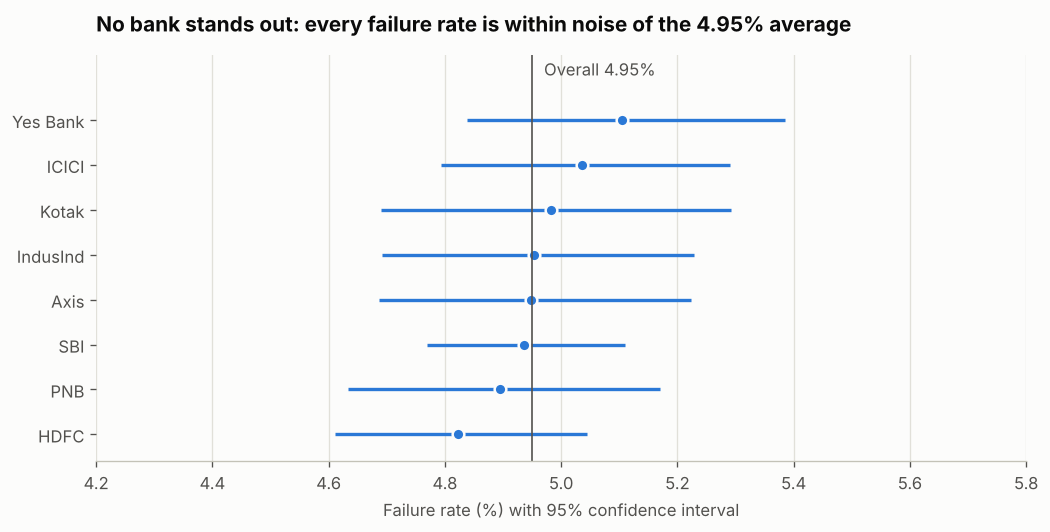

,transactions,failures,rate,ci_low,ci_high
sender_bank,,,,,
Yes Bank,24860,1269,5.10,4.84,5.39
ICICI,29769,1499,5.04,4.79,5.29
Kotak,20032,998,4.98,4.69,5.29
IndusInd,25173,1247,4.95,4.69,5.23
Axis,25042,1239,4.95,4.69,5.22
SBI,62693,3095,4.94,4.77,5.11
PNB,24946,1221,4.89,4.63,5.17
HDFC,37485,1808,4.82,4.61,5.04


In [8]:
def wilson(k, n, z=1.96):
    # 95% Wilson confidence interval for a proportion
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

bank = df.groupby("sender_bank")["is_failed"].agg(failures="sum", transactions="count")
bank["rate"] = bank["failures"] / bank["transactions"] * 100
ci = [wilson(k, n) for k, n in zip(bank["failures"], bank["transactions"])]
bank["ci_low"] = [c[0] * 100 for c in ci]
bank["ci_high"] = [c[1] * 100 for c in ci]
bank = bank.sort_values("rate")
overall = df["is_failed"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 4.4))
y = np.arange(len(bank))
ax.hlines(y, bank["ci_low"], bank["ci_high"], color=BLUE, linewidth=2)
ax.plot(bank["rate"], y, "o", color=BLUE, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.axvline(overall, color=INK_2, linewidth=1)
ax.text(overall + 0.02, len(bank) - 0.1, f"Overall {overall:.2f}%", color=INK_2, va="bottom", ha="left")
ax.set_yticks(y)
ax.set_yticklabels(bank.index)
ax.set_ylim(-0.6, len(bank) + 0.45)
ax.set_xlim(4.2, 5.8)
ax.set_xlabel("Failure rate (%) with 95% confidence interval")
ax.grid(axis="y", visible=False)
ax.set_title(f"No bank stands out: every failure rate is within noise of the {overall:.2f}% average")
plt.show()

covers = ((bank["ci_low"] <= overall) & (overall <= bank["ci_high"])).all()
print("Every bank's interval covers the overall rate:", bool(covers))
bank[["transactions", "failures", "rate", "ci_low", "ci_high"]].sort_values("rate", ascending=False)

The chart covers one attribute. The next cell tests **every** attribute in the dataset against both outcomes (failure and fraud flag). When you run many tests, some look significant by luck, so the table also shows a Bonferroni-adjusted p-value (the raw p-value multiplied by the number of tests).

In [9]:
def rate_test(group, outcome):
    table = pd.crosstab(group, df[outcome])
    if table.shape == (2, 2):
        return "Fisher exact", fisher_exact(table)[1]
    return "Chi-square", chi2_contingency(table)[1]

attributes = {
    "Sender bank": df["sender_bank"],
    "Device type": df["device_type"],
    "Network type": df["network_type"],
    "Merchant category": df["merchant_category"],
    "Transaction type": df["transaction type"],
    "Sender age group": df["sender_age_group"],
    "Sender state": df["sender_state"],
    "Weekend": df["is_weekend"],
    "Month": df["month"],
    "High value (above ₹5,000)": df["high_value"],
}

rows = []
for name, column in attributes.items():
    for outcome, label in [("is_failed", "Failure"), ("fraud_flag", "Fraud flag")]:
        test, p = rate_test(column, outcome)
        rows.append({"Attribute": name, "Outcome": label, "Test": test, "p": p})

tests = pd.DataFrame(rows).sort_values("p").reset_index(drop=True)
n_tests = len(tests)
tests["Adjusted p"] = (tests["p"] * n_tests).clip(upper=1)
tests["Significant after correction?"] = np.where(tests["Adjusted p"] < 0.05, "Yes", "No")
print(f"{n_tests} tests run. Bonferroni threshold: 0.05 / {n_tests} = {0.05 / n_tests:.4f}")
print("Raw p-values below 0.05:", int((tests["p"] < 0.05).sum()))
print("Significant after correction:", int((tests["Adjusted p"] < 0.05).sum()))

shown = tests.copy()
shown["p"] = shown["p"].map("{:.4f}".format)
shown["Adjusted p"] = shown["Adjusted p"].map("{:.3f}".format)
shown

20 tests run. Bonferroni threshold: 0.05 / 20 = 0.0025
Raw p-values below 0.05: 3
Significant after correction: 0


,Attribute,Outcome,Test,p,Adjusted p,Significant after correction?
0,"High value (above ₹5,000)",Fraud flag,Fisher exact,0.0133,0.266,No
1,Sender age group,Fraud flag,Chi-square,0.0255,0.510,No
2,Weekend,Failure,Fisher exact,0.0412,0.823,No
3,"High value (above ₹5,000)",Failure,Fisher exact,0.0556,1.000,No
4,Sender age group,Failure,Chi-square,0.1174,1.000,No
5,Month,Failure,Chi-square,0.1605,1.000,No
6,Sender state,Failure,Chi-square,0.2016,1.000,No
7,Sender bank,Fraud flag,Chi-square,0.2384,1.000,No
8,Network type,Failure,Chi-square,0.2778,1.000,No
9,Month,Fraud flag,Chi-square,0.3270,1.000,No


### Insight 4: failures and fraud flags are not explained by any attribute in this data

**Finding:** Failure rates are about 5% everywhere, and no attribute reliably separates "risky" from "safe" groups.
**Evidence:** The overall failure rate is 4.95%. Banks range from 4.82% (HDFC) to 5.10% (Yes Bank), and every bank's confidence interval covers the overall rate (chi-square p = 0.86). Across all 20 tests, three raw p-values fall below 0.05 (about one would be expected by chance alone), and none is significant after correction.
**So what:** A league table of "worst banks" built from this data would mostly rank noise. A 0.15 percentage-point gap on a bank like Yes Bank is only about 38 payments.
**Recommended action:** Do not act on bank or segment rankings from this data. Collect failure reason codes (bank decline, timeout, insufficient balance, network error), because without a cause the failure rate cannot be diagnosed.

## 6. One lead worth investigating: high-value payments

Fraud-flag rate: Fisher exact p = 0.0133
Failure rate:    Fisher exact p = 0.0556
Fraud p after correcting for 20 tests: 0.27


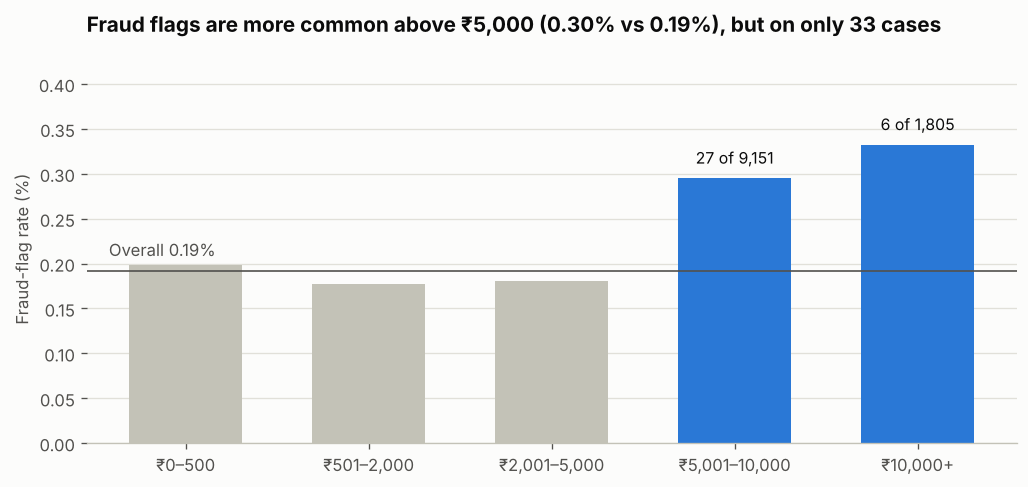

,transactions,failures,Failure rate %,fraud_flagged,Fraud-flag rate %
high_value,,,,,
"Up to ₹5,000",239044,11791,4.93,447,0.19
"Above ₹5,000",10956,585,5.34,33,0.30


In [10]:
b = df.groupby("amount_band", observed=True).agg(n=("fraud_flag", "size"), flagged=("fraud_flag", "sum"))
b["rate"] = b["flagged"] / b["n"] * 100
overall_fraud = df["fraud_flag"].mean() * 100

hv = df.groupby("high_value").agg(transactions=("is_failed", "size"),
                                  failures=("is_failed", "sum"),
                                  fraud_flagged=("fraud_flag", "sum"))
hv["Failure rate %"] = hv["failures"] / hv["transactions"] * 100
hv["Fraud-flag rate %"] = hv["fraud_flagged"] / hv["transactions"] * 100
hv.index = hv.index.map({False: "Up to ₹5,000", True: "Above ₹5,000"})

fig, ax = plt.subplots(figsize=(10, 4.2))
cols = [BLUE if i >= 3 else GRAY for i in range(len(b))]
ax.bar(range(len(b)), b["rate"], color=cols, width=0.62)
ax.set_xticks(range(len(b)))
ax.set_xticklabels(b.index)
for i in (3, 4):
    ax.text(i, b["rate"].iloc[i] + 0.012, f"{int(b['flagged'].iloc[i])} of {b['n'].iloc[i]:,}",
            ha="center", va="bottom", fontsize=9.5)
ax.axhline(overall_fraud, color=INK_2, linewidth=1)
ax.text(-0.42, overall_fraud + 0.012, f"Overall {overall_fraud:.2f}%", color=INK_2, ha="left", va="bottom")
ax.set_ylabel("Fraud-flag rate (%)")
ax.set_ylim(0, b["rate"].max() * 1.3)
ax.grid(axis="x", visible=False)
hi, lo = hv.loc["Above ₹5,000"], hv.loc["Up to ₹5,000"]
ax.set_title(f"Fraud flags are more common above ₹5,000 ({hi['Fraud-flag rate %']:.2f}% vs "
             f"{lo['Fraud-flag rate %']:.2f}%), but on only {int(hi['fraud_flagged'])} cases")
plt.show()

p_fraud = fisher_exact(pd.crosstab(df["high_value"], df["fraud_flag"]))[1]
p_fail = fisher_exact(pd.crosstab(df["high_value"], df["is_failed"]))[1]
print(f"Fraud-flag rate: Fisher exact p = {p_fraud:.4f}")
print(f"Failure rate:    Fisher exact p = {p_fail:.4f}")
print(f"Fraud p after correcting for {n_tests} tests: {min(1, p_fraud * n_tests):.2f}")
hv[["transactions", "failures", "Failure rate %", "fraud_flagged", "Fraud-flag rate %"]]

### Insight 5: fraud flags lean towards high-value payments, but this is a lead and not a conclusion

**Finding:** Payments above ₹5,000 are flagged more often.
**Evidence:** The fraud-flag rate is 0.30% above ₹5,000 (33 of 10,956) vs 0.19% below (447 of 239,044), with Fisher exact p = 0.013. The failure rate is also slightly higher (5.34% vs 4.93%, p = 0.056, not significant).
**Caution:** This is one of 20 tests. After correcting for that, p is about 0.27, and only 33 flagged cases back the result. It is a hypothesis to test, not a proven pattern.
**Recommended action:** Pilot extra checks on high-value payments and validate the pattern on data with confirmed fraud labels before changing any rules.

## 7. Is there a trend or seasonality?

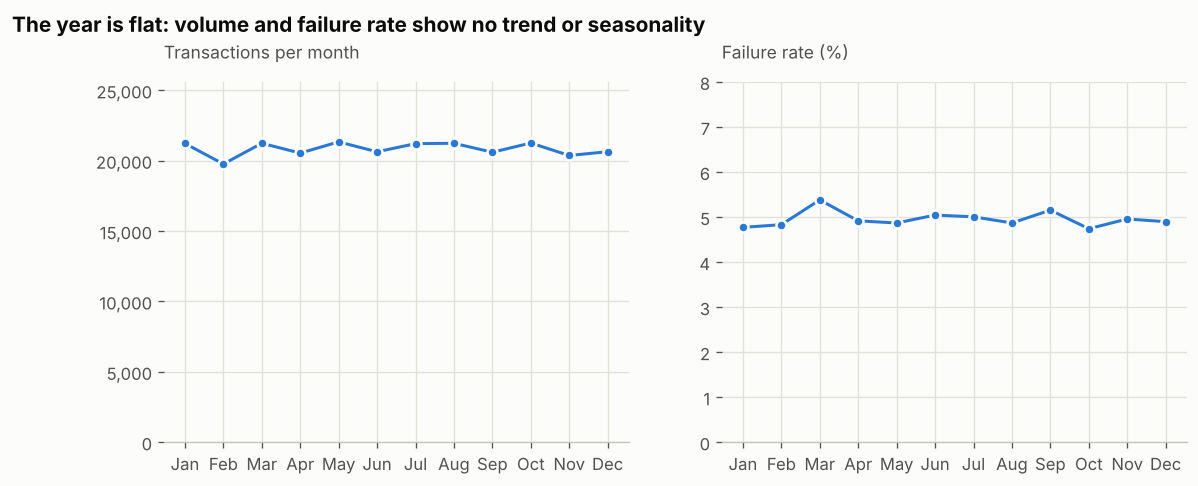

,transactions,days_in_data,transactions_per_day,failure_rate
month,,,,
2024-01,21221,31,684.55,4.77
2024-02,19759,29,681.34,4.83
2024-03,21234,31,684.97,5.38
2024-04,20536,30,684.53,4.91
2024-05,21333,31,688.16,4.87
2024-06,20628,30,687.60,5.04
2024-07,21207,31,684.10,5.00
2024-08,21231,31,684.87,4.87
2024-09,20597,30,686.57,5.15


In [11]:
mon = df.groupby("month").agg(transactions=("is_failed", "size"), failure_rate=("is_failed", "mean"))
mon["failure_rate"] = mon["failure_rate"] * 100
mon["days_in_data"] = df.groupby("month")["timestamp"].apply(lambda s: s.dt.date.nunique())
mon["transactions_per_day"] = mon["transactions"] / mon["days_in_data"]
labels = pd.to_datetime(mon.index).strftime("%b")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
axes[0].plot(labels, mon["transactions"], color=BLUE, linewidth=1.8, marker="o", markersize=6,
             markeredgecolor=SURFACE, markeredgewidth=1.5)
axes[0].set_ylim(0, mon["transactions"].max() * 1.2)
axes[0].set_title("Transactions per month", fontsize=10.5, fontweight="normal", color=INK_2)
axes[1].plot(labels, mon["failure_rate"], color=BLUE, linewidth=1.8, marker="o", markersize=6,
             markeredgecolor=SURFACE, markeredgewidth=1.5)
axes[1].set_ylim(0, 8)
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
axes[1].set_title("Failure rate (%)", fontsize=10.5, fontweight="normal", color=INK_2)
fig.suptitle("The year is flat: volume and failure rate show no trend or seasonality",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold", y=1.03)
plt.show()

mon[["transactions", "days_in_data", "transactions_per_day", "failure_rate"]]

### Insight 6: no trend, no seasonality

**Finding:** Monthly volume and failure rate stay in a narrow band all year.
**Evidence:** Monthly volume ranges from 19,759 to 21,333, and the failure rate from 4.74% to 5.38%. February looks low only because it has fewer days: transactions per day are about the same every month. The month attribute is not significant in the test table above.
**So what:** There are no seasonal peaks or growth trends to plan around in this dataset. Real UPI traffic grows and has festival spikes, which is one more reason this data is synthetic.
**Recommended action:** Re-run this analysis on real monthly NPCI statistics to see whether the real trend matches.

## 8. Summary and recommendations

| # | Insight | Key evidence | Recommended action |
|---|---|---|---|
| 1 | Payments peak in the evening | 17:00–20:59 holds 31.3% of transactions | Maintenance at 03:00–05:00, capacity and alerting for the evening |
| 2 | A few large payments carry the value | Top 10% of payments = 43% of value; ₹10,000+ is 0.7% of count but 7.4% of value | Report and monitor by value as well as count |
| 3 | Category rankings differ by count and value | Education 3.0% of count vs 11.8% of value | Prioritise reliability by value at risk |
| 4 | Failures are not explained by any attribute | Failure rate about 5% everywhere; 0 of 20 tests significant after correction | Do not rank banks on this data; collect failure reason codes |
| 5 | High-value payments are flagged slightly more | 0.30% vs 0.19% (33 cases); does not survive correction | Pilot extra checks, validate on confirmed fraud labels |
| 6 | No trend or seasonality | Flat volume (about 680–690 per day) and failure rate | Compare with real NPCI monthly data |

## 9. Limitations and next steps

**Limitations**
- The data is synthetic, so patterns (and the lack of them) say little about real UPI behaviour.
- The fraud flag is a dataset label, not confirmed fraud, and there are only 480 flagged cases.
- There are no failure reason codes, customer IDs or merchant IDs, so causes and repeat behaviour cannot be studied.
- Many tests were run on one dataset, so results are corrected for multiple testing and read cautiously.

**Next steps**
- Compare monthly volume with the real NPCI monthly statistics (the file loaded in the original notebook).
- Add failure reason codes and confirmed fraud labels if a real dataset allows it.
- Build the Power BI Recommendations page from the summary table above.